In [94]:
# Источник истины: этот файл. Сборка: make sync-notebooks.

# ЛР1. Вариант 1. От полного градиента к mini-batch SGD

Сегодня превращаем одну идею из лекции в собственный работающий компонент.
Данные, предобработка, визуализация и обёртки уже готовы. Сначала маленький пример, затем код и эксперимент.

## Одна ЛР1, два занятия, от 0 до 10 баллов

Это **одна лабораторная работа на два занятия и самостоятельное завершение дома**.
Вы выполняете только назначенный вариант. Начать часть A можно после лекции 2;
часть B завершайте после лекций 3–4. Два этапа не оцениваются как две разные работы.

| За что | Баллы |
|---|---:|
| Часть A: корректный базовый компонент и его проверки | 3.5 |
| Сквозной эксперимент с собственным базовым компонентом | 1.0 |
| Объяснение базового решения на защите | 0.5 |
| Часть B: расширенный контракт и его проверки | 2.5 |
| Контролируемый эксперимент и содержательный вывод | 1.5 |
| Объяснение расширения и небольшое изменение на защите | 1.0 |
| **Максимум** | **10.0** |

Законченный базовый маршрут даёт **до 5/10**, полный — **до 10/10**. Частичные баллы
внутри строки зависят от реально работающих частей; провал одного теста не обнуляет всё.

**Что сдаём:** сохранённый `.ipynb`, собственные выводы и сгенерированный файл прогнозов
на закрытой тестовой части.
Не меняйте тесты, служебные функции и фиксированное разбиение ради прохождения проверки.

## Как пользоваться заготовкой
`MODE = "base"` — часть A; `MODE = "full"` — A и B. Не ставьте `full`, пока расширение не готово.
`NotImplementedError` означает явно незавершённую работу: проверки и зависимый эксперимент
покажут «НЕ ВЫПОЛНЕНО», а не подставят библиотечное решение. Настоящие ошибки и неверные
`assert` останавливают выполнение и требуют исправления. После правок перезапустите kernel.
В разделе `Референсный baseline` готовая модель отмечена отдельно и не считается вашим кодом.

In [95]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_predict, cross_validate
from sklearn.utils.validation import check_is_fitted

# Готовый поиск корня: notebook можно открыть из своей подпапки.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if ((p / "materials/01-regression/code/course_support.py").is_file()
                 and (p / "materials/02-data/datasets/support-tickets/student/tickets_lab1_dev.csv").is_file())
             or ((p / "course_support.py").is_file()
                 and (p / "data/tickets_lab1_dev.csv").is_file())), None)
if ROOT is None:
    raise FileNotFoundError("Распакуйте весь комплект; нужны данные ЛР1 и course_support.py.")
SUPPORT = ROOT if (ROOT / "course_support.py").is_file() else ROOT / "materials/01-regression/code"
if str(SUPPORT) not in sys.path:
    sys.path.insert(0, str(SUPPORT))
from course_support import (
    TARGET, FEATURES, NUMERIC, CATEGORICAL, BLUE, load_tables, make_preprocessor,
    augment, check_arrays, record, result_dict, run_checks, mse, metrics,
    NormalizedRidge, IterativeRegressor, baseline_pipeline,
    plot_history, plot_residuals, plot_target, export_predictions,
)

In [96]:
VARIANT = 1
MODE = "full"
EXPORT_FINAL = True

In [97]:
assert MODE in {"base", "full"}
checks = {}

## От знакомой задачи к более интересным данным

`маркер=DATA`. **Код готов; прочитайте, затем запустите**

Как в первом семинаре, предсказываем `resolution_minutes` **при регистрации обращения**.
Исходный `intro_tickets.csv` сохранён без изменений: 480 строк, три числовых признака и target.
Здесь используем **новый синтетический набор**, а не дополнительные реальные обращения
и не переименованную копию исходных ответов. Словарь полей находится в паспорте набора данных.

Добавлены канал и тема обращения, число вложений, число работающих операторов,
выходной день и размер первого запроса в байтах. Есть пропуски, близкие по информации
признаки, нелинейный эффект высокой очереди и неодинаковый шум. Это учебные предположения,
не утверждения о реальной службе поддержки.

Фиксированы 1440 строк train, 480 validation и 480 test. В студенческом test **нет target**.
Разбиение случайное для специально сгенерированных независимых обращений; переносить
его автоматически на реальные временные или клиентские данные нельзя.

Предобработка готова: числовые пропуски → медиана train; числовые масштабы → статистики
train; категории → готовое кодирование. Если эти компоненты пока незнакомы, используйте
их как готовую цепочку; на семинаре 2 вернёмся к их смыслу. `ticket_id` не входит в признаки.

Train / validation / test: 1440 480 480


,ticket_id,message_length,queue_at_open,account_age_days,attachments_count,active_agents,is_weekend,initial_payload_bytes,channel,topic,resolution_minutes
0,L1-00001,107,19,948.0,0,9.0,0,244.0,email,integration,129.64
1,L1-00003,332,5,587.0,1,8.0,1,731.0,email,integration,85.58
2,L1-00004,1767,17,1000.0,0,5.0,1,3715.0,email,billing,161.39
3,L1-00005,514,0,1432.0,2,10.0,0,1109.0,email,billing,47.81


,Пропуски на train
message_length,0
queue_at_open,0
account_age_days,67
attachments_count,0
active_agents,51
is_weekend,0
initial_payload_bytes,88
channel,0
topic,32


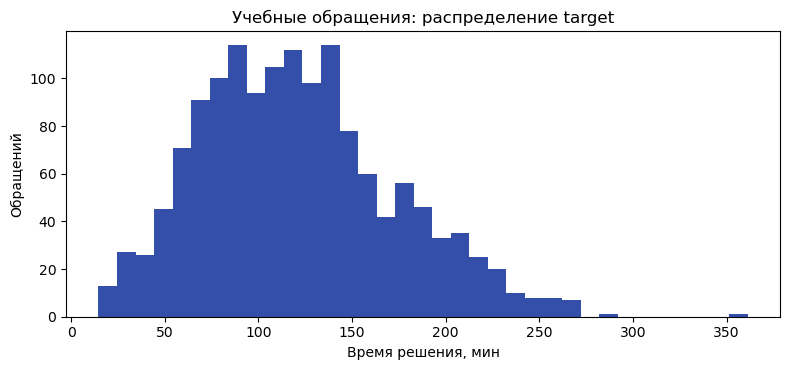

In [98]:
train, valid, test = load_tables(ROOT)
X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_valid, y_valid = valid[FEATURES], valid[TARGET].to_numpy()
print("Train / validation / test:", len(train), len(valid), len(test))
display(train.head(4))
display(train[FEATURES].isna().sum().rename("Пропуски на train").to_frame())
plot_target(train)

## Модель и обозначения

$X$ — числовые входы после предобработки, $X\in\mathbb R^{n\times d}$;
$y\in\mathbb R^n$ — ответы. Внутри оптимизатора используем
$Z=[\mathbf 1\;X]$ и $\theta=(b,w_1,\ldots,w_d)^\top$.
Тогда $\hat y=Z\theta$; нулевая координата — **свободный член**, а не дополнительный измеренный признак.

$$J(\theta)=\frac1n\|Z\theta-y\|_2^2+\lambda\sum_{j=1}^{d}\theta_j^2.$$

В части A $\lambda=0$. Для частей с регуляризацией параметр `l2` означает именно $\lambda$.
MSE и $J$ измеряются здесь в квадратных минутах; MAE и RMSE — в минутах.
**Метрика проверки и критерий обучения — не одно и то же.**

## Референсный baseline — готовый, не ваша реализация
Библиотечное решение нужно для масштаба ошибки и сравнения
Здесь `l2=0`, то есть нерегуляризованная линейная задача. Медианный baseline полезен по MAE,
но для MSE естественная константа — среднее train; ниже показаны обе метрики одного среднего прогноза.

In [99]:
library_model = baseline_pipeline(l2=0.0).fit(X_train, y_train)
library_prediction = library_model.predict(X_valid)
display(pd.DataFrame([
    {"модель": "Среднее train", **metrics(y_valid, np.full(len(y_valid), y_train.mean()))},
    {"модель": "Библиотечная линейная модель", **metrics(y_valid, library_prediction)},
]))

,модель,"MSE, мин²","RMSE, мин","MAE, мин"
0,Среднее train,2492.046651,49.920403,40.880665
1,Библиотечная линейная модель,217.102785,14.734408,10.826191


## Часть A. Полный градиент — до 5/10 вместе с экспериментом и объяснением
`маркер=A1`. **После лекции 2, самостоятельно**

Модель и критерий уже заданы. Осталось выполнить последовательность шагов
$$\theta_{t+1}=\theta_t-\eta\nabla J(\theta_t).$$
Ниже значение критерия и градиент **даны**: вы отвечаете за алгоритм обучения, а не за их вывод.

In [100]:
def objective_gradient(Z, y, theta, l2=0.0):
    """Готовый критерий для вариантов оптимизации; b = theta[0] не штрафуется."""
    residual = Z @ theta - y
    penalty = theta.copy()
    penalty[0] = 0.0
    value = np.mean(residual**2) + l2 * np.dot(penalty, penalty)
    gradient = (2.0 / len(y)) * (Z.T @ residual) + 2.0 * l2 * penalty
    return float(value), gradient

### Разобранный пример: один шаг

Пусть $Z=\begin{pmatrix}1&1\\1&2\end{pmatrix}$, $y=(2,4)^\top$, $\theta_0=(0,0)^\top$.
Остатки «прогноз − ответ» равны $(-2,-4)^\top$; градиент равен $(-6,-10)^\top$.
При $\eta=0.1$ получаем $\theta_1=(0.6,1)^\top$. Это один шаг, а не найденный минимум.

**Контракт `full_batch_descent`:** начальный вектор — нулевой; ровно `steps` обновлений;
входы не изменяются. История содержит начальное состояние и запись после каждого шага.
`updates` — число шагов; `seen` — число объектов, использованных в обучающих градиентах.
Служебный расчёт полной ошибки для графика в `seen` не учитывается; это не измерение wall time.
Допустим `steps=0`: возвращается начальное состояние. `eta>0`, `l2>=0`.
Используйте готовые `record` и `result_dict`, чтобы не писать инфраструктуру.

In [101]:
def full_batch_descent(Z, y, *, eta=0.05, steps=120, l2=0.0):
    Z, y = check_arrays(Z, y)
    if eta <= 0 or steps < 0 or l2 < 0:
        raise ValueError("eta>0, steps>=0, l2>=0")
    theta = np.zeros(Z.shape[1])
    history = []
    record(history, theta, objective_gradient(Z, y, theta, l2)[0], 0, 0)
    
    for i in  range(steps):
        _, gradient = objective_gradient(Z, y, theta, l2)
        theta = theta - eta * gradient
        loss = objective_gradient(Z, y, theta, l2)[0]
        record(history, theta, loss, i + 1, (i + 1) * len(y))

    return result_dict(theta, history, steps, steps*len(y))

In [102]:
def check_full_batch():
    Z = np.array([[1., 1.], [1., 2.]])
    y = np.array([2., 4.]); Z_copy = Z.copy(); y_copy = y.copy()
    first = full_batch_descent(Z, y, eta=.1, steps=1)
    np.testing.assert_allclose(first["theta"], [.6, 1.])
    assert first["updates"] == 1 and first["seen"] == 2
    assert len(first["history"]) == 2
    zero = full_batch_descent(Z, y, eta=.1, steps=0)
    np.testing.assert_array_equal(zero["theta"], [0., 0.])
    assert zero["updates"] == zero["seen"] == 0
    for l2 in (0.,):
        fitted = full_batch_descent(Z, y, eta=.05, steps=1000, l2=l2)
        ref = NormalizedRidge(l2=l2).fit(Z[:, 1:], y)
        np.testing.assert_allclose(Z @ fitted["theta"], ref.predict(Z[:, 1:]), atol=2e-3)
    np.testing.assert_array_equal(Z, Z_copy); np.testing.assert_array_equal(y, y_copy)
checks["A1"] = run_checks("A1 / базовый solver", check_full_batch)

A1 / базовый solver: проверки пройдены (это не автоматическая итоговая оценка).


### Подключаем собственный solver
`IterativeRegressor` — готовый адаптер с `fit/predict`. Он сам добавляет столбец единиц
**после** предобработки. Внутри `fit` вызывается именно ваша функция.
Ошибка может отличаться от библиотечной: фиксированное число шагов не гарантирует сходимость.

,модель,"MSE, мин²","RMSE, мин","MAE, мин"
0,Свой полный GD,235.616765,15.349813,11.348589
1,Библиотечная,217.102785,14.734408,10.826191


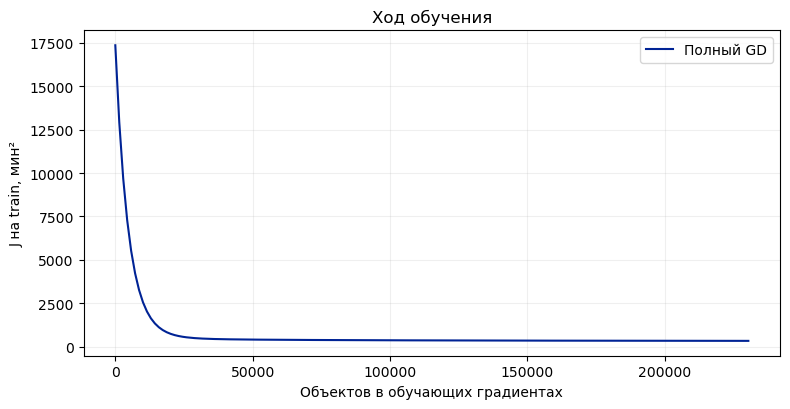

In [103]:
basic_model = None
final_model = None
if checks["A1"]:
    basic_model = make_pipeline(make_preprocessor(), IterativeRegressor(
        solver=full_batch_descent, solver_params={"eta": .05, "steps": 160, "l2": 0.0}))
    basic_model.fit(X_train, y_train)
    final_model = basic_model
    display(pd.DataFrame([
        {"модель": "Свой полный GD", **metrics(y_valid, basic_model.predict(X_valid))},
        {"модель": "Библиотечная", **metrics(y_valid, library_prediction)},
    ]))
    plot_history({"Полный GD": basic_model[-1].result_})
else:
    print("Сквозной эксперимент A ждёт A1; baseline не выдан за ваше решение.")

**Остановка после первой пары.** Сохраните работающий базовый маршрут.
Объясните, что означают последняя строка истории и число `seen`. Если часть A не закончена,
продолжите её дома; переход к B не должен скрывать ошибки A.

## Часть B. Шумный градиент и бюджет вычислений — ещё до 5 баллов
`маркер=B1`. **Вторая часть, после лекций 3–4**

Для пакета $B_t$ заменяем полный градиент оценкой по его объектам.
Вызов `objective_gradient(Z[ids], y[ids], theta, l2)` уже правильно делит на размер **этого** пакета.

$$\eta_t=\frac{\eta_0}{1+\gamma t},\qquad t=0,1,2,\ldots$$

$t$ — глобальный номер обновления, **не** эпохи; на первой итерации шаг равен $\eta_0$.
Одна эпоха — один проход по всем train-объектам. Пары `Z/y` перемешиваются одной перестановкой.

**Пример.** При $n=23$, размере пакета 8, без перемешивания пакеты имеют размеры 8, 8 и 7.
За две эпохи: 6 обновлений и 46 обработанных объектов. Последние 7 объектов не выбрасываем.
Пакет больше выборки означает один полный пакет.

Реализуйте `make_batches` и `mini_batch_descent`. Генератор `rng` создаётся **один раз**
до цикла эпох; повторная инициализация seed в каждой эпохе повторяет перестановки.
Историю здесь пишем только в начале и после эпохи, а не после каждого пакета.

In [ ]:
def make_batches(n, batch_size, rng, shuffle=True):
    if n <= 0 or batch_size <= 0:
        raise ValueError("n и batch_size должны быть положительными")
    
    indx = np.arange(n)

    if shuffle:
        rng.shuffle(indx)

    batches = [indx[i:i + batch_size] for i in range(0, n, batch_size)]

    return batches

def mini_batch_descent(Z, y, *, eta=0.03, epochs=40, batch_size=32,
                       decay=0.002, seed=17, shuffle=True, l2=0.0):
    Z, y = check_arrays(Z, y)
    if eta <= 0 or epochs < 0 or decay < 0 or l2 < 0 or batch_size <= 0:
        raise ValueError("Недопустимые параметры")
    theta = np.zeros(Z.shape[1]); history = []
    rng = np.random.default_rng(seed)
    updates = seen = 0
    record(history, theta, objective_gradient(Z, y, theta, l2)[0], updates, seen)
    
    for i in range(epochs):
        batches = make_batches(len(y), batch_size, rng, shuffle)
        for el in batches:
            _, gradient = objective_gradient(Z[el], y[el], theta, l2)
            new_eta = eta / (1.0 + decay * (updates))
            theta = theta - new_eta * gradient

            updates += 1
            seen += len(el)
        
        loss, _ = objective_gradient(Z, y, theta, l2)
        record(history, theta, loss, updates, seen)

    

    return result_dict(theta, history, updates, seen)

In [105]:
def check_minibatch():
    parts = make_batches(23, 8, np.random.default_rng(5), shuffle=False)
    assert [len(p) for p in parts] == [8, 8, 7]
    np.testing.assert_array_equal(np.concatenate(parts), np.arange(23))
    shuffled = make_batches(23, 8, np.random.default_rng(5), shuffle=True)
    np.testing.assert_array_equal(np.sort(np.concatenate(shuffled)), np.arange(23))
    np.testing.assert_array_equal(np.concatenate(shuffled),
        np.concatenate(make_batches(23, 8, np.random.default_rng(5), shuffle=True)))
    rng = np.random.default_rng(11)
    Z = augment(rng.normal(size=(23, 3))); y = rng.normal(size=23)
    params = dict(eta=.03, epochs=5, decay=0., l2=.1)
    mb = mini_batch_descent(Z, y, batch_size=100, shuffle=False, **params)
    gd = full_batch_descent(Z, y, eta=.03, steps=5, l2=.1)
    np.testing.assert_allclose(mb["theta"], gd["theta"])
    result = mini_batch_descent(Z, y, epochs=2, batch_size=8)
    assert result["updates"] == 6 and result["seen"] == 46
    assert len(result["history"]) == 3
    repeat = mini_batch_descent(Z, y, epochs=2, batch_size=8)
    np.testing.assert_array_equal(result["theta"], repeat["theta"])
    scalar = mini_batch_descent(np.ones((3, 1)), np.ones(3), eta=.1, epochs=2,
                                batch_size=3, decay=.5, shuffle=False)
    np.testing.assert_allclose(scalar["theta"], [.2 + (1.6 / 15.)])
checks["B1"] = run_checks("B1 / mini-batch", check_minibatch) if MODE == "full" else False
if MODE == "base": print("Часть B пропущена явно: MODE='base'.")

B1 / mini-batch: проверки пройдены (это не автоматическая итоговая оценка).


### Один контролируемый эксперимент
До запуска запишите ожидание: как отличаются траектории при пакете 32 и полном пакете?
Используем одинаковые 40 проходов по данным, начальный шаг .03, seed 17 и `l2=.03`.
Для сравнения размеров пакета фиксируем `decay=0`: иначе частота обновлений одновременно
меняет расписание. Затухающий шаг уже проверен отдельно; его можно исследовать дополнительно.

Выберите конфигурацию по **validation MSE**, не по обучающему $J$.
Дополнительно повторите малый пакет с seed 29, не выбирая более красивый seed.
На графике `seen` не учтена стоимость мониторинга: это число объектов в градиентах,
а не доказательство ускорения в секундах.

In [106]:
hypothesis = "При фулл батче будет сделано 40 обновлений, при мини батче - 1800(при количестве эпох в 40 штук), mini-batch быстрее сойдется и будет чуть лучше"  

,конфигурация,"MSE, мин²","RMSE, мин","MAE, мин",updates,seen
0,batch=32,241.340949,15.535152,11.565474,1800,57600
1,batch=1440,369.234486,19.215475,14.473047,40,57600


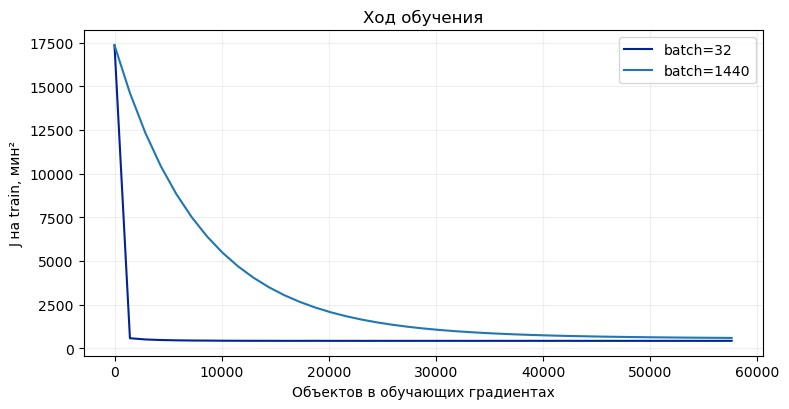

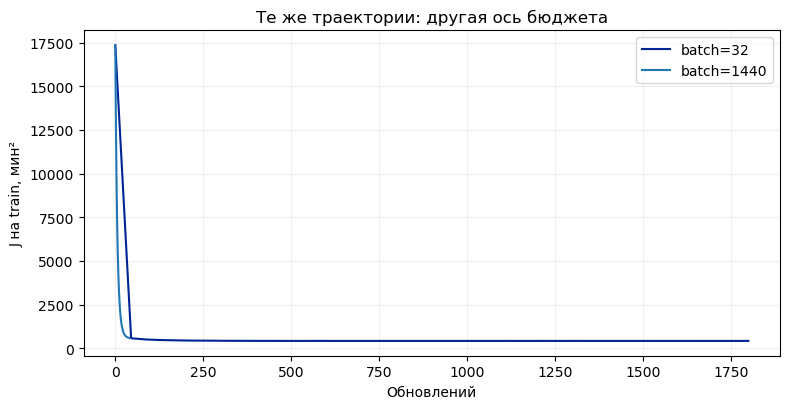

Выбрано по validation MSE: batch=32
Диагностический seed 29 (не новый выбор победителя): {'MSE, мин²': 234.9662980031473, 'RMSE, мин': 15.328610439408632, 'MAE, мин': 11.267704190664961}


In [107]:
experiment = None
if MODE == "full" and checks["A1"] and checks["B1"]:
    rows, fitted, histories = [], {}, {}
    for size in (32, len(y_train)):
        candidate = make_pipeline(make_preprocessor(), IterativeRegressor(
            mini_batch_descent, {"eta": .03, "epochs": 40, "batch_size": size,
                                 "decay": 0., "seed": 17, "l2": .03}))
        candidate.fit(X_train, y_train)
        label = f"batch={size}"
        fitted[label] = candidate; histories[label] = candidate[-1].result_
        rows.append({"конфигурация": label, **metrics(y_valid, candidate.predict(X_valid)),
                     "updates": candidate[-1].result_["updates"], "seen": candidate[-1].result_["seen"]})
    experiment = pd.DataFrame(rows)
    display(experiment)
    plot_history(histories, x="seen")
    plot_history(histories, x="updates", title="Те же траектории: другая ось бюджета")
    best_label = experiment.loc[experiment["MSE, мин²"].idxmin(), "конфигурация"]
    final_model = fitted[best_label]
    print("Выбрано по validation MSE:", best_label)
    second_seed = make_pipeline(make_preprocessor(), IterativeRegressor(
        mini_batch_descent, {"eta": .03, "epochs": 40, "batch_size": 32,
                             "decay": 0., "seed": 29, "l2": .03})).fit(X_train, y_train)
    print("Диагностический seed 29 (не новый выбор победителя):", metrics(y_valid, second_seed.predict(X_valid)))
else:
    print("Расширенный эксперимент не выполнен; доступен базовый маршрут при готовой A1.")

## finally

1. Что реализовано мной и какие ограничения остались?
2. Что сравнивалось, что было зафиксировано, какую метрику использовали?
3. Какой результат получился **с числами** и совпал ли с ожиданием?
4. Где именно проходил `fit` и какие данные участвовали в выборе настроек?
5. Почему результат не доказывает качество на всех будущих обращениях?

Пройдите `Restart Kernel → Run All`. Статус незавершённой части допустим только для
явно выбранного базового маршрута; библиотечный baseline не заменяет вашу модель.

In [ ]:
conclusion = """
1) написано разбиение на батчи + градиентый спуск по минибатчам и обычным батчам
2) сравнивался mini-batch(32) и full-batch, остальные параметры(шаг, seed и т.п.) отсались неизменны, MSE
3) предполагалось, что full-batch будет плавнее сходится(правда), у mini batch будет больше обновлений и результат немного лучше(правда) 234 vs 241
4) fit проходил на train выборках, для выбора настроек использовалась val выборка
5) все зависит от данных, на которых обучается модель. Также не мало важную роль играет выбор гиперпараметров (l2, shuffle, seed и т. п.). 
 

"""  # 4–8 предложений по вопросам выше.
print("Вывод заполнен:", bool(conclusion.strip()))
print("Проверки:", checks)
print("Заявленный маршрут:", MODE, "| максимум маршрута:", 5 if MODE == "base" else 10)

Вывод заполнен: True
Проверки: {'A1': True, 'B1': True}
Заявленный маршрут: full | максимум маршрута: 10


### Одна финальная проверка
Сначала закончите выбор настроек. Только затем поставьте `EXPORT_FINAL=True` и выполните
ячейку ниже.
**Низкая test-ошибка не является порогом получения баллов.**

In [109]:
if EXPORT_FINAL:
    if final_model is None:
        raise RuntimeError("Сначала получите собственную работающую final_model.")
    export_predictions(ROOT, test, final_model.predict(test[FEATURES]), "lab1_v1_predictions.csv")
else:
    print("Test не использован: EXPORT_FINAL=False.")

Сохранено: C:\Users\АРТЕМ\Desktop\Mephi\MlLabs(man)\lab1\submissions\lab1_v1_predictions.csv


## Справка
Ссылки нужны для дальнейшего чтения; выполнение notebook не требует интернета.
- [NumPy: `lstsq`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)
- [scikit-learn: SGD](https://scikit-learn.org/stable/modules/sgd.html)
- [scikit-learn: ошибки предобработки и утечки](https://scikit-learn.org/stable/common_pitfalls.html)

Внешний API похож на scikit-learn, но учебный solver не является полной копией `SGDRegressor`:
отличаются инициализация, нормировка критерия, расписание шага и критерии остановки.